# Neural credit-card fraud detection

Variant 14 of the tabular neural-network assignment. Acceptance: genuine data; seed 42 train/validation/test; train-only imputation/scaling; LightGBM baseline; two PyTorch MLP configurations selected by validation average precision with early stopping; untouched test evaluation; PCA, t-SNE and UMAP; reloadable saved artifacts.

Data: [official TensorFlow tutorial and public CSV mirror](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data), originally ULB/Worldline [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud). The unchanged source has 284,807 rows and 492 frauds, with Time, V1–V28, Amount and Class. V1–V28 are already anonymised PCA features. No categorical columns exist, so categorical mode/label encoding and nn.Embedding are inapplicable.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import pandas as pd
from fraud import load_data, run, projections
raw = load_data()
print(raw.shape, 'fraud:', int(raw.Class.sum()))
display(raw.head(), raw.isna().sum().to_frame('missing').T)


(284807, 31) fraud: 492


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
missing,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Leakage control and training

Remove exact duplicate transactions before a stratified 60/20/20 split. This prevents identical records in separate partitions. Keep validation and test at their natural deduplicated prevalence. For CPU efficiency, retain all training frauds and sample 30,000 training normals; report both prevalences explicitly. Fit median imputation and StandardScaler on this training subset only. No synthetic data are introduced.

Train two MLPs with BatchNorm, ReLU, Dropout, Adam and BCEWithLogitsLoss weighted by the *used training* class ratio. Batch size 256; at most 35 epochs; patience 5 on validation AP. Compare 128–64/dropout .2/lr .001 and 64–32/dropout .4/lr .0005. Validation AP selects the checkpoint and architecture. The selected model is not refit on validation. Choose each model's F1 threshold on validation only. Test is used only after all choices. CPU PyTorch wheel is intentional on this machine; the device check is recorded below and CUDA is used if available in a compatible installation.

In [2]:
data, preprocessing, features, report = run()
display(pd.DataFrame(report['split']).T)
print('Device:', report['device'], 'duplicates removed:', report['duplicates_removed'])
print('Selected:', report['selected_config'], 'epoch:', report['best_epoch'])
display(pd.DataFrame(report['test']).T)
print('Validation AP:', report['validation_ap'])


MLP {'widths': [128, 64], 'dropout': 0.2, 'lr': 0.001} best epoch 12 validation AP 0.8111139966717515


MLP {'widths': [64, 32], 'dropout': 0.4, 'lr': 0.0005} best epoch 10 validation AP 0.7638500735467908


,rows,fraud,prevalence
train_full,170235.0,284.0,0.001668
train_used,30284.0,284.0,0.009378
validation,56745.0,94.0,0.001657
test,56746.0,95.0,0.001674


Device: cpu duplicates removed: 1081
Selected: {'widths': [128, 64], 'dropout': 0.2, 'lr': 0.001} epoch: 12


,roc_auc,average_precision,f1,accuracy,threshold,confusion_matrix
mlp,0.959869,0.717185,0.811429,0.999418,0.996229,"[[56642, 9], [24, 71]]"
lightgbm,0.971304,0.791736,0.816092,0.999436,0.973013,"[[56643, 8], [24, 71]]"


Validation AP: {'mlp': 0.8111139966717515, 'lightgbm': 0.8714401105328256}


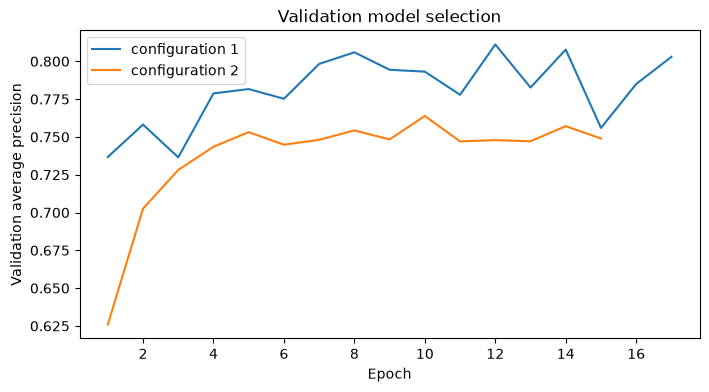

In [3]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8,4))
for i, history in enumerate(report['histories']):
    ax.plot([r['epoch'] for r in history], [r['validation_ap'] for r in history], label=f'configuration {i+1}')
ax.set(xlabel='Epoch', ylabel='Validation average precision', title='Validation model selection')
ax.legend(); plt.show()


## Descriptive projections

Project 2,500 sampled normal transactions and 400 sampled frauds, using the fitted training scaler. PCA retains all 30 available dimensions before nonlinear projections (the requirement is up to 50); plot its first two axes separately. The enriched 2,900-row sample intentionally improves visibility of the rare class and does not estimate real prevalence. The same observations and labels are used by all three plots; labels do not fit the projections. These descriptive plots cover data from all splits and are created after test evaluation; they do not influence model selection.

C:\Users\t-pud\AppData\Local\Temp\prod-me-neural-fraud-detection-20261023\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


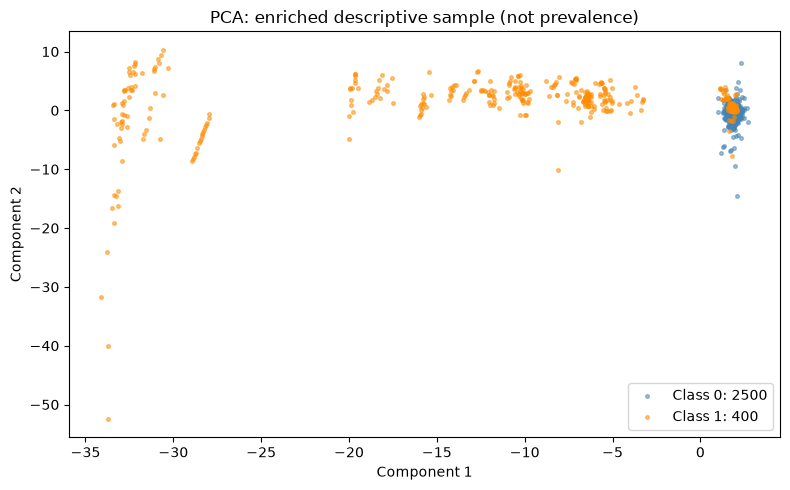

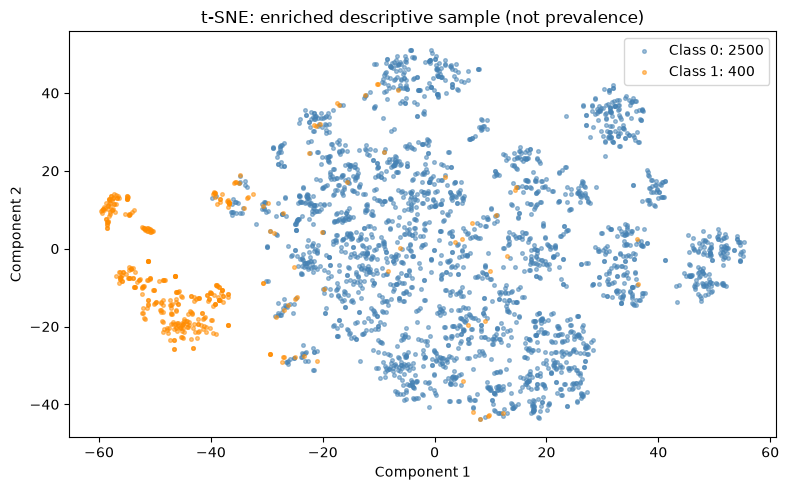

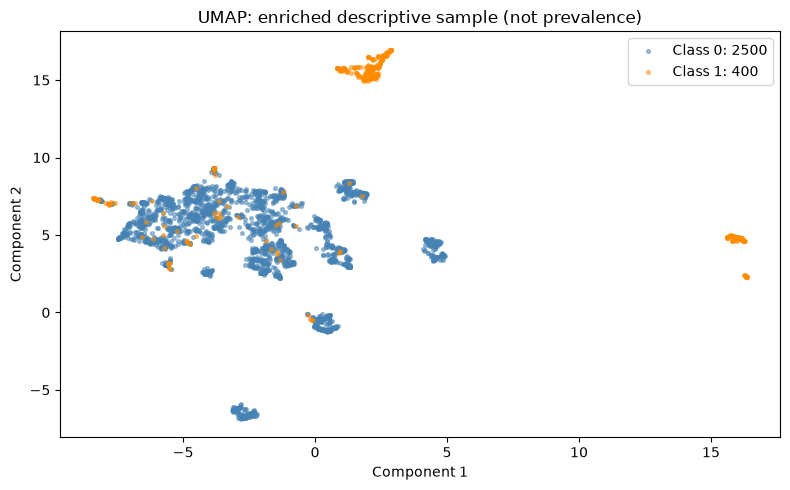

PCA components: 30 ; first two explained variance: 0.5842305348778155


In [4]:
projections(data, preprocessing, features)

## Interpretation and limits

The executed run selected the 128-64 MLP at epoch 12 (validation AP .811114); the smaller configuration reached .763850. Test AP is .717185 for MLP versus .791736 for LightGBM, so the boosting baseline ranks the rare frauds better on this split. Both detect 71/95 test frauds at validation-selected thresholds; false positives are 9 and 8 respectively.

In these plots, PCA places many frauds far from the dense normal cloud but retains overlapping cases near its centre. t-SNE and UMAP show fraud-rich regions as well as fraudulent observations embedded among normal transactions. This supports partial structure, not complete separation.

Accuracy is dominated by normal transactions; ROC-AUC and especially average precision reveal rare-event ranking quality. F1 and confusion matrices refer to validation-selected thresholds. Training undersampling and class weighting alter the learned probability prior: scores are useful for ranking but are not calibrated operational fraud probabilities. The representative test prevalence is therefore essential.

PCA shows the strongest linear variation; overlap in two axes cannot prove that the original 30-dimensional problem is inseparable. t-SNE and UMAP emphasise local neighbourhoods and may form islands even in continuous data. Apparent class concentrations can suggest structure, but neither island distances nor visual separation prove generalisation. The random transaction split is educational; a time-based evaluation and stronger transaction/customer grouping would be needed for deployment. Duplicate removal changes the original benchmark population and the exact counts are reported above. Saved weights and preprocessing are round-trip checked before success.